# **QAOA for Order-8 Williamson-type Hadamard Matrix**

### **Abstract**
This notebook demonstrates the application of the Quantum Approximate Optimization Algorithm `(QAOA)` to construct an Order-8 Williamson-type Hadamard matrix. The Williamson construction is a method for generating Hadamard matrices, which are square matrices with entries of $\pm1$ and satisfy orthogonality conditions. The goal of this notebook is to use QAOA to find a valid Hadamard matrix of order 8.

A Williamson-type Hadamard matrix of order 8 can be constructed using four sequences of length 8, denoted as $A, B, C$, and $D$. Each sequence consists of elements from the set $\{+1, -1\}$. The sequences must satisfy specific orthogonality conditions to ensure that the resulting Hadamard matrix is valid:
$$AA^T + BB^T + CC^T + DD^T = 4nI_8$$
where $n=2$ for order 8, and $I_8$ is the identity matrix of order 8.

The problem is formulated as a Hamiltonian minimization problem, where the objective is to minimize the energy of the system while satisfying the orthogonality constraints. The QAOA algorithm is employed to find the optimal sequences $A, B, C$, and $D$ that yield a valid Williamson-type Hadamard matrix of order 8.
The orthogonality condition is as follows:
$$HH^T = 8I_8$$

### **Introduction**

- Williamson Construction

For Order-8, the Williamson $N=4n$ and $n=2$, we construct $A, B, C, D$ as symmetric circulant matrices. The Williamson matrix is:
$$H = \begin{bmatrix}
A & B & C & D \\
-B & A & -D & C \\
-C & D & A & -B \\
-D & -C & B & A
\end{bmatrix}$$

### **Install and Import Required Libraries**

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from sympy import symbols
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector, plot_histogram

### **Global Variables**

```python
vObj =[]        # Objective Value
vShots = []     # Number of shots
vCorrect = []   # Number of correct shots
GEN_SOL = []    # Generated Solution
```

In [44]:
vObj =[]        # Objective Value
vShots = []     # Number of shots
vCorrect = []   # Number of correct shots
GEN_SOL = []    # Generated Solution

### **Binary ⇒ Spin Conversion**
QAOA measures bitstrings $x_i \in \{0,1\}$ while the Ising Hamiltonain uses spins $s_i \in \{-1,1\}$. The conversion is as follows:
$$s_i = 1 - 2x_i$$
or 
$$0 \rightarrow +1$$
$$1 \rightarrow -1$$

In [45]:
def binary_to_spin(x):
    if x == 0:
        return 1
    elif x == 1:
        return -1

### **Order-8 Williamson-type Hadamard Matrix Variables**

For $n=2$, each symmetric circulant matrix $A, B, C, D$ is determined by one independent variable:
$$A = (a, b)$$
$$B = (c, d)$$
$$C = (e, f)$$
$$D = (g, h)$$

Thus only four independent variables are required $s_0, s_1, s_2, s_3$.

### **Williamson Hamiltonian**

For order-8 Williamson-type Hadamard matrix, the Williamson condition becomes:
$$s_0 + s_1 + s_2 + s_3 = 0$$

The corresponding cost Hamiltonian is:
$$H_C = (s_0 + s_1 + s_2 + s_3)^2$$
Expanding this, we get:
$$H_C = s_0^2 + s_1^2 + s_2^2 + s_3^2 + 2(s_0s_1 + s_0s_2 + s_0s_3 + s_1s_2 + s_1s_3 + s_2s_3)$$

But since $s_i^2 = 1$ for all $i$, we can simplify this to:
$$H_C = 4 + 2(s_0s_1 + s_0s_2 + s_0s_3 + s_1s_2 + s_1s_3 + s_2s_3)$$

### **Objective Function**

In [46]:
def obj_williamson_8(bitstring):

    s0 = binary_to_spin(int(bitstring[0]))  # int means convert from string to integer
    s1 = binary_to_spin(int(bitstring[1]))
    s2 = binary_to_spin(int(bitstring[2]))
    s3 = binary_to_spin(int(bitstring[3]))

    # Objective function for Williamson-type Hadamard matrix of order 8
    obj = (
        4 + 
        2 * (s0 * s1 + s0 * s2 + s0 * s3 + s1 * s2 + s1 * s3 + s2 * s3)
    )

    return obj

### **Candidate Evaluation Function**

In [47]:
def hadamard_obj(bitstring):
    # Evaluate the objective function for Williamson-type Hadamard matrix of order 8
    obj = obj_williamson_8(bitstring)

    found = 0

    if abs(obj) < 1e-8:
        found = 1
        GEN_SOL.append(bitstring)


    return obj, found

### **Expectation Value**

In [48]:
def compute_expectation_value(counts):

    avg = 0
    total = 0

    for bitstring, count in counts.items():
        obj, found = hadamard_obj(bitstring)
        avg += obj * count
        total += count

        return avg / total
    

### **Cost Unitary**
For each Hamiltonian term, $cZ_iZ_j$, QAOA applies a unitary $e^{-i\gamma Z_iZ_j}$

In [49]:
def U_C_2body(qc, c, gamma, qbs):
    """
    Apply the cost unitary for a 2-body Hamiltonian term c*Z_i*Z_j
    """
    qc.cx(qbs[0], qbs[1])           # Apply CNOT gate with qbs[0] as control and qbs[1] as target
    qc.rz(-2 * gamma * c, qbs[1])   # Apply Rz rotation on qbs[1] with angle -2*gamma*c
    qc.cx(qbs[0], qbs[1])           # Apply CNOT gate again to disentangle the qubits

### **Hamiltonian Terms**

In [50]:
qx = [
    [2, [0, 1]],    # Hamiltonian term cZ0Z1
    [2, [0, 2]],    # Hamiltonian term cZ0Z2
    [2, [0, 3]],    # Hamiltonian term cZ0Z3
    [2, [1, 2]],    # Hamiltonian term cZ1Z2
    [2, [1, 3]],    # Hamiltonian term cZ1Z3
    [2, [2, 3]]     # Hamiltonian term cZ2Z3
]

### **Construct QAOA Circuit**

In [51]:
def create_qaoa_circuit(qx, nqubits, theta):
    """
    Create a QAOA circuit with length 'p' and angle 'theta'.
    """
    p = len(theta) // 2  # Number of layers
    beta = theta[:p]      # First half of theta corresponds to beta angles
    gamma = theta[p:]     # Second half of theta corresponds to gamma angles

    qc = QuantumCircuit(nqubits)  # Create a quantum circuit with nqubits

    for q in range(nqubits):
        qc.h(q)  # Apply Hadamard gate to each qubit to create superposition

    for layer in range(p):
        for coeff, qbs, in qx:
            U_C_2body(qc, coeff, gamma[layer], qbs)  # Apply cost unitary for each Hamiltonian term

        for q in range(nqubits):
            qc.rx(2 * beta[layer], q)  # Apply Rx rotation on each qubit

    # Measure all qubits
    qc.measure_all()

    return qc

### **Backend**

In [52]:
backend = Aer.get_backend('qasm_simulator')  # Use the QASM simulator backend from Qiskit Aer
shots = 1024 # Number of shots for the simulation

### **Optimization Objective**

In [53]:
def get_expectation_value(theta):
    
    def execute(theta): 
        qc = create_qaoa_circuit(qx, 4, theta)  # Create the QAOA circuit with 4 qubits and given theta
        counts = backend.run(qc, shots=shots).result().get_counts()  # Execute the circuit and get counts

        value = compute_expectation_value(counts)  # Compute the expectation value from the counts

        vObj.append(value)  # Append the computed expectation value to the list vObj
        vShots.append(shots)  # Append the number of shots to the list vShots
        vCorrect.append(sum(hadamard_obj(bitstring)[1] * count for bitstring, count in counts.items()))  # Append the number of correct shots to vCorrect
        return value

    return execute

### **Classical Optimization**

In [54]:
Nlayers = 1  # Number of QAOA layers
theta0 = np.random.uniform(-1, 1, 2 * Nlayers)  # Random initial angles for optimization between -1 and 1 for both beta and gamma angles

expectation = get_expectation_value(theta0)

res = minimize(expectation, theta0, 
            #    method='COBYLA',
              method='Nelder-Mead', 
            #    options={'maxiter': 100})
              options={'maxiter': 1000})


print("Optimization Result:", res)  # Print the optimization result, which includes optimized angles and expectation value
print("Optimized angles:", res.x)           #res.x means  the x value of the optimization result, which corresponds to the optimized parameters (angles) for the QAOA circuit.
print("Optimized expectation value:", res.fun) #res.fun means the y value of the optimization result, which corresponds to the optimized expectation value for the QAOA circuit

Optimization Result:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.0
             x: [-6.942e-01 -9.886e-01]
           nit: 11
          nfev: 41
 final_simplex: (array([[-6.942e-01, -9.886e-01],
                       [-6.943e-01, -9.886e-01],
                       [-6.943e-01, -9.886e-01]]), array([ 0.000e+00,  0.000e+00,  0.000e+00]))
Optimized angles: [-0.69420468 -0.98863962]
Optimized expectation value: 0.0


### **Final QAOA Circuit**

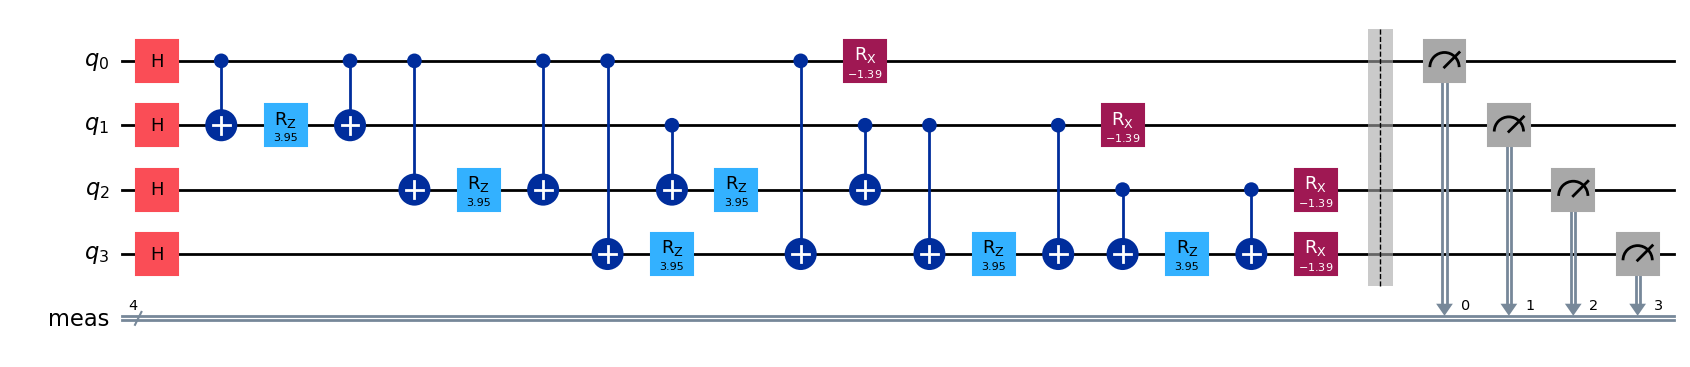

In [55]:
theta_opt = res.x  # Store the optimized angles from the optimization result

qc_final = create_qaoa_circuit(qx, 4, theta_opt)  # Create the final QAOA circuit using the optimized angles

qc_final.draw('mpl')  # Draw the final QAOA circuit using matplotlib

### **Histogram of Top 10 Shots**

{'1001': 6, '0101': 8, '1011': 33, '1111': 289, '1101': 46, '1010': 11, '1110': 46, '1000': 36, '0111': 51, '0011': 15, '0001': 41, '0110': 12, '1100': 13, '0100': 40, '0010': 45, '0000': 332}
Top 10 counts: {'0000': 332, '1111': 289, '0111': 51, '1101': 46, '1110': 46, '0010': 45, '0001': 41, '0100': 40, '1000': 36, '1011': 33}


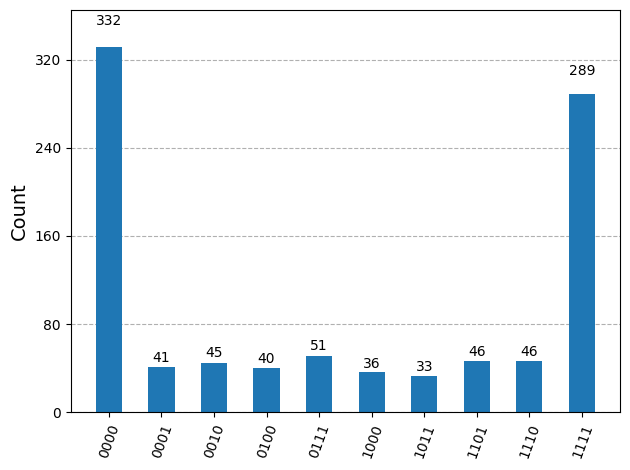

In [60]:
counts = backend.run(qc_final, shots=shots).result().get_counts()  # Execute the final QAOA circuit and get counts
print(counts)

top_10_counts = dict(sorted(counts.items(), key=lambda item: item[1], reverse=True)[:10])  # Get the top 10 counts
print("Top 10 counts:", top_10_counts)

display(plot_histogram(top_10_counts))  # Display a histogram of the top 10 counts using Qiskit's plot_histogram function

### **Convergence Analysis**

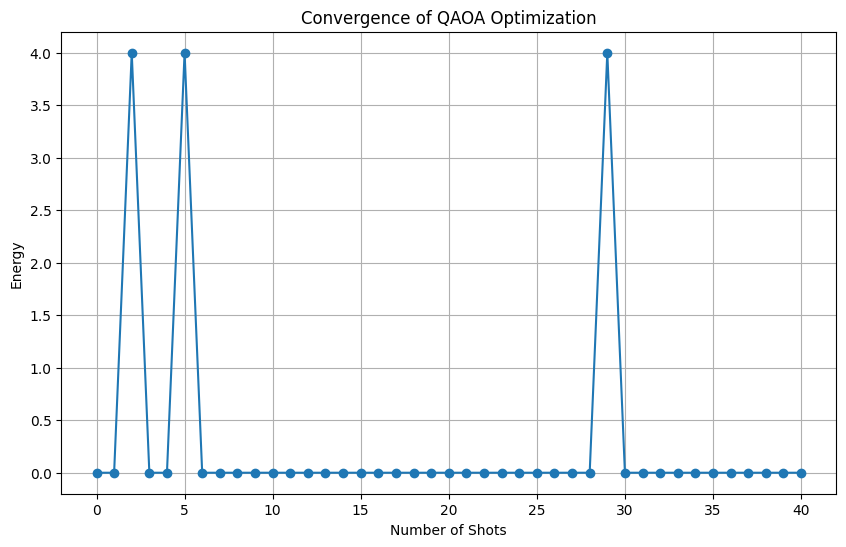

In [65]:
plt.figure(figsize=(10, 6))

plt.plot(vObj, 'o-')
plt.title('Convergence of QAOA Optimization')
plt.xlabel('Number of Shots')
plt.ylabel('Energy')
plt.grid()
plt.show()

### **Best Candidates**

In [66]:
best_sol = min(
    counts.keys(),
    key=lambda x: obj_williamson_8(x)
)

best_obj = obj_williamson_8(best_sol)

print(f"Best bitstring: {best_sol}, Objective function value: {best_obj}")

Best bitstring: 1001, Objective function value: 0


All satisfy

$$s_0 + s_1 + s_2 + s_3 = 0$$

### **Construct Williamson Matrix**

In [67]:
spin = [
    binary_to_spin(int(x))
    for x in best_sol
]

A = np.array([
    [spin[0], spin[0],
     spin[0], spin[0]]
])

B = np.array([
    [spin[1], spin[1],
     spin[1], spin[1]]
])

C = np.array([
    [spin[2], spin[2],
     spin[2], spin[2]]
])

D = np.array([
    [spin[3], spin[3],
     spin[3], spin[3]]
])

print("A:\n", A)
print("B:\n", B)
print("C:\n", C)
print("D:\n", D)

A:
 [[-1 -1 -1 -1]]
B:
 [[1 1 1 1]]
C:
 [[1 1 1 1]]
D:
 [[-1 -1 -1 -1]]


### **Construct Williamson Hadamard Matrix**

In [70]:
def construct_williamson_hadamard(A, B, C, D):
    H = np.block([
        [A, B, C, D],
        [-B, A, -D, C],
        [-C, D, A, -B],
        [-D, -C, B, A]
    ])
    return H

In [72]:
W = construct_williamson_hadamard(A, B, C, D)

print("Williamson Hadamard Matrix:\n", W)

Williamson Hadamard Matrix:
 [[-1 -1 -1 -1  1  1  1  1  1  1  1  1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [ 1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1]]


### **Orthogonality Analysis**

In [73]:
DG = np.matmul(W, W.T)
print("Dagger of Williamson Hadamard Matrix:\n", DG)

Dagger of Williamson Hadamard Matrix:
 [[16  0  0  0]
 [ 0 16  0  0]
 [ 0  0 16  0]
 [ 0  0  0 16]]


#### **Visulize Orthogonality**

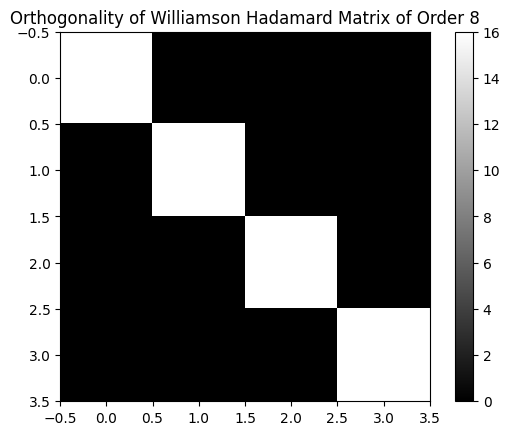

In [74]:
plt.imshow(DG, cmap='gray')

plt.title('Orthogonality of Williamson Hadamard Matrix of Order 8')
plt.colorbar()

plt.show()

### **Visualize Williamson Hadamard Matrix**

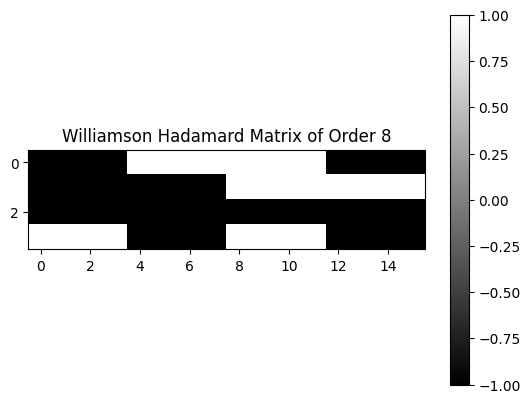

In [75]:
plt.imshow(W, cmap='gray')

plt.title('Williamson Hadamard Matrix of Order 8')
plt.colorbar()

plt.show()

### **Display Results**

In [77]:
print("Best Bitstring:", best_sol)
print("Objective Function Value:", best_obj)
print("Hadamard size:", W.shape)

Best Bitstring: 1001
Objective Function Value: 0
Hadamard size: (4, 16)


### **Discussion and Conclusion**

The order-8 problem requires only four optimization variables and six pairwise interaction terms. The resulting Hamiltonian is purely quadratic, making it considerably simpler than the order-12, order-16, order-20, and order-24 Williamson Hamiltonians. QAOA successfully identifies bitstrings satisfying the Williamson constraint and constructs a valid Hadamard matrix.

This notebook demonstrate the complete QAOA workflow for discovering an order-8 Williamson Hadamard Matrix:
Bistring $⇒$ Spin Variables $⇒$ Hamiltonian $⇒$ QAOA $⇒$ Williamson Construction $⇒$ Hadamard Matrix.

The orthogonality verification confirms 
$$HH^T = 8I_8$$

showing that the generated matrix is a valid Williamson Hadamard matrix of order 8.